# The Ultimate OpenCV 7-Day Bootcamp: Professional Mastery
This notebook is an incredibly comprehensive, professional-grade reference designed to prepare you decisively for the final round of the Quera Image Processing Olympiad.
Even if you haven't written a single line of OpenCV code before, studying the theories and running the code in this file will give you a deep, practical understanding of how computer vision algorithms work at the pixel level.

### Image Structure in Computers (Basic Theory)
In the computer world, an image is nothing more than a mathematical matrix of numbers. Each point (pixel) is represented by a value between 0 and 255 (in 8-bit images). 
Color images consist of three matrix layers (channels) stacked together. In standard libraries like Matplotlib, these layers are **R** (Red), **G** (Green), and **B** (Blue). However, for historical reasons, OpenCV reads these channels as **BGR**.

**Our Roadmap:**
* **Day 1:** Image Basics, Color Spaces, Histograms, Pixel Manipulation, Drawing, and Blending
* **Day 2:** Spatial Filters, Noise Types, Thresholding, Image Pyramids, and Fourier Transform
* **Day 3:** Edge Detection, Gradients (Sobel), and the Smart Canny Algorithm
* **Day 4:** Advanced Morphology, Contours, Geometric Object Analysis, and Moments
* **Day 5:** Hough Transform, Line/Circle Extraction, Analytical Geometry Functions
* **Day 6:** Geometric Transforms (Affine/Perspective), Template Matching, and Synthetic Datasets
* **Day 7:** Phase 1 Project (End-to-End, robust error-resistant pipeline)

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
import random

plt.rcParams['figure.figsize'] = (10, 6)

def show_image(img, title="Image", cmap=None):
    plt.figure(figsize=(6, 4))
    plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()

## Day 1 — Processing Basics, Color Spaces, Drawing, and Bitwise Operations

### 1. Utility Functions
To avoid code repetition, we write functions that increase the safety and readability of our pipeline.
* `cv2.imread(filepath)`: Reads an image from the disk. Returns `None` if the file doesn't exist.
* `cv2.cvtColor(src, code)`: Color space conversion. The `code` determines the type (e.g., `cv2.COLOR_BGR2RGB`).
* `cv2.resize(src, dsize, fx, fy, interpolation)`: Resizes an image. 
    * `dsize`: New dimensions (width, height).
    * `interpolation`: The interpolation algorithm. `cv2.INTER_AREA` (averaging pixel areas) offers the best quality for downsampling (shrinking). For upscaling, `cv2.INTER_CUBIC` (slow but high quality) or `cv2.INTER_LINEAR` (default) is used.

### 2. Extracting Region of Interest (ROI)
Since an image is a NumPy array, no special function is needed to crop it. We simply use matrix slicing: `img[y_start:y_end, x_start:x_end]`.

In [13]:
def load_image(filepath, as_rgb=True):
    img = cv2.imread(filepath)
    if img is None: raise ValueError(f"Not found: {filepath}")
    if as_rgb: img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img

def resize_keep_ratio(img, target_width=None, target_height=None):
    h, w = img.shape[:2]
    if target_width: 
        dim = (target_width, int(h * (target_width / w)))
    else: 
        dim = (int(w * (target_height / h)), target_height)
    return cv2.resize(img, dim, interpolation=cv2.INTER_AREA)

def extract_roi(img, x, y, w, h):
    return img[y:y+h, x:x+w]

def show_images_grid(images, titles, rows, cols, figsize=(15, 10), cmap=None):
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    if rows * cols == 1: axes = np.array([axes])
    for i, (img, title) in enumerate(zip(images, titles)):
        ax = axes.flatten()[i]
        ax.imshow(img, cmap=cmap)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### 3. Drawing Shapes, Channels, Bitwise Operations, and Color Filtering
Bitwise operations are heavily used in image processing for masking (isolating specific regions).
* **`cv2.ellipse(img, center, axes, angle, startAngle, endAngle, color, thickness)`**:
  * `center`: `(x,y)` coordinates of the ellipse center.
  * `axes`: `(major, minor)` axis lengths.
  * `angle`: Overall rotation of the ellipse. `startAngle` and `endAngle` draw a specific arc.
  * `thickness`: Line thickness. `-1` creates a filled shape.
* **`cv2.polylines(img, [pts], isClosed, color, thickness)`**: Draws polygons. `pts` is an array of coordinates with shape `(N, 1, 2)`. `isClosed=True` connects the last point back to the first.
* **`cv2.putText(..., lineType=cv2.LINE_AA)`**: Renders text. The `LINE_AA` (Anti-Aliased) parameter ensures the text edges are drawn smoothly without pixelated artifacts.
* **Color Filtering with `cv2.inRange(hsv, lower, upper)`**: Creates a binary mask where pixels falling inside the `lower` to `upper` bounds become pure white (255) and the rest become black (0).
* **`cv2.bitwise_and(src1, src2, mask)`**: Performs a logical `AND` on pixels. By passing a `mask`, the operation only extracts the regions corresponding to the white parts of the mask.

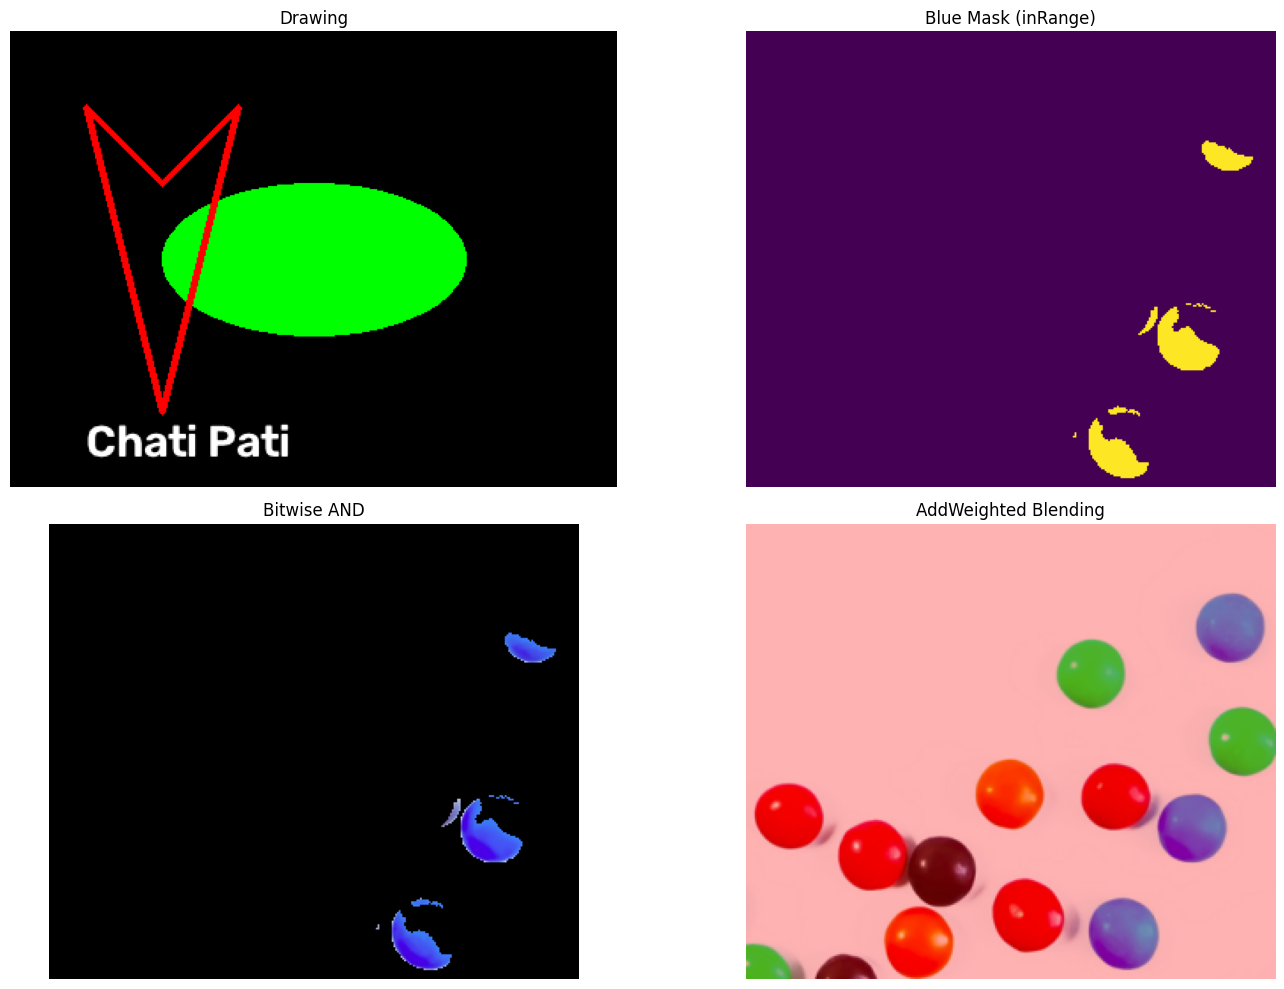

In [14]:
img_smarties = load_image('data/images/smarties.png')
img_smarties = resize_keep_ratio(img_smarties, target_width=300)

# Drawing
canvas = np.zeros((300, 400, 3), dtype=np.uint8)
cv2.ellipse(canvas, (200, 150), (100, 50), 0, 0, 360, (0, 255, 0), -1)
pts = np.array([[50, 50], [100, 100], [150, 50], [100, 250]], np.int32).reshape((-1,1,2))
cv2.polylines(canvas, [pts], True, (255, 0, 0), 3)
cv2.putText(canvas, 'Chati Pati', (50, 280), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2, cv2.LINE_AA)

# Split and Merge Channels
r, g, b = cv2.split(img_smarties)
img_merged = cv2.merge((r, g, b))

# Color Filtering (Masking Blue Smarties)
hsv_smarties = cv2.cvtColor(img_smarties, cv2.COLOR_RGB2HSV)
lower_blue = np.array([110, 50, 50])
upper_blue = np.array([130, 255, 255])
mask_blue = cv2.inRange(hsv_smarties, lower_blue, upper_blue)

# Bitwise Operations
mask_inv = cv2.bitwise_not(mask_blue) # Invert mask
isolated_blue = cv2.bitwise_and(img_smarties, img_smarties, mask=mask_blue) # Apply mask

# Alpha Blending: dst = img1 * alpha + img2 * beta + gamma
canvas_blend = np.full_like(img_smarties, (255, 0, 0)) # Pure red image
blended = cv2.addWeighted(img_smarties, 0.7, canvas_blend, 0.3, 0)

show_images_grid([canvas, mask_blue, isolated_blue, blended],
    ['Drawing', 'Blue Mask (inRange)', 'Bitwise AND', 'AddWeighted Blending'], 2, 2)

## Day 2 — Filters, Thresholding, Image Pyramids, and Fourier Transform

### 1. Filters and Noise
Spatial Filtering alters a pixel based on the values of its neighboring pixels.
* **`cv2.filter2D(src, ddepth, kernel)`**: The core convolution function that applies an arbitrary matrix (kernel) to the image. `ddepth=-1` keeps the output depth identical to the input.
* **`cv2.boxFilter`**: Takes a simple neighborhood average. Setting `normalize=True` ensures the kernel values sum to 1 so the overall brightness is preserved.
* **`cv2.GaussianBlur`**: Instead of a flat average, it gives higher weight to the central pixel. Excellent for mitigating sensor noise.
* **`cv2.medianBlur`**: Calculates the "median" value instead of the mean. It is the absolute best solution for Salt & Pepper noise.
* **`cv2.bilateralFilter`**: A highly advanced filter that aggressively blurs textures while strictly preserving sharp structural edges.

### 2. Thresholding
Converting a grayscale image into a binary (absolute black and white) image. `cv2.threshold(img, thresh, maxval, type)`:
* `THRESH_BINARY`: If pixel > `thresh`, it becomes `maxval`; otherwise, 0.
* `THRESH_BINARY_INV`: The inverse of binary thresholding.
* `THRESH_TRUNC`: Values exceeding the threshold are truncated (capped) at the threshold value.
* `THRESH_TOZERO`: Values below the threshold become 0 (black); otherwise, they remain unchanged.
* **Otsu's Method**: Adding `cv2.THRESH_OTSU` forces the algorithm to mathematically find the optimal global threshold automatically.
* **`cv2.adaptiveThreshold`**: Perfect for images with uneven lighting or shadows. The threshold for a pixel is calculated based on its localized surrounding block (e.g., an 11x11 pixel window).

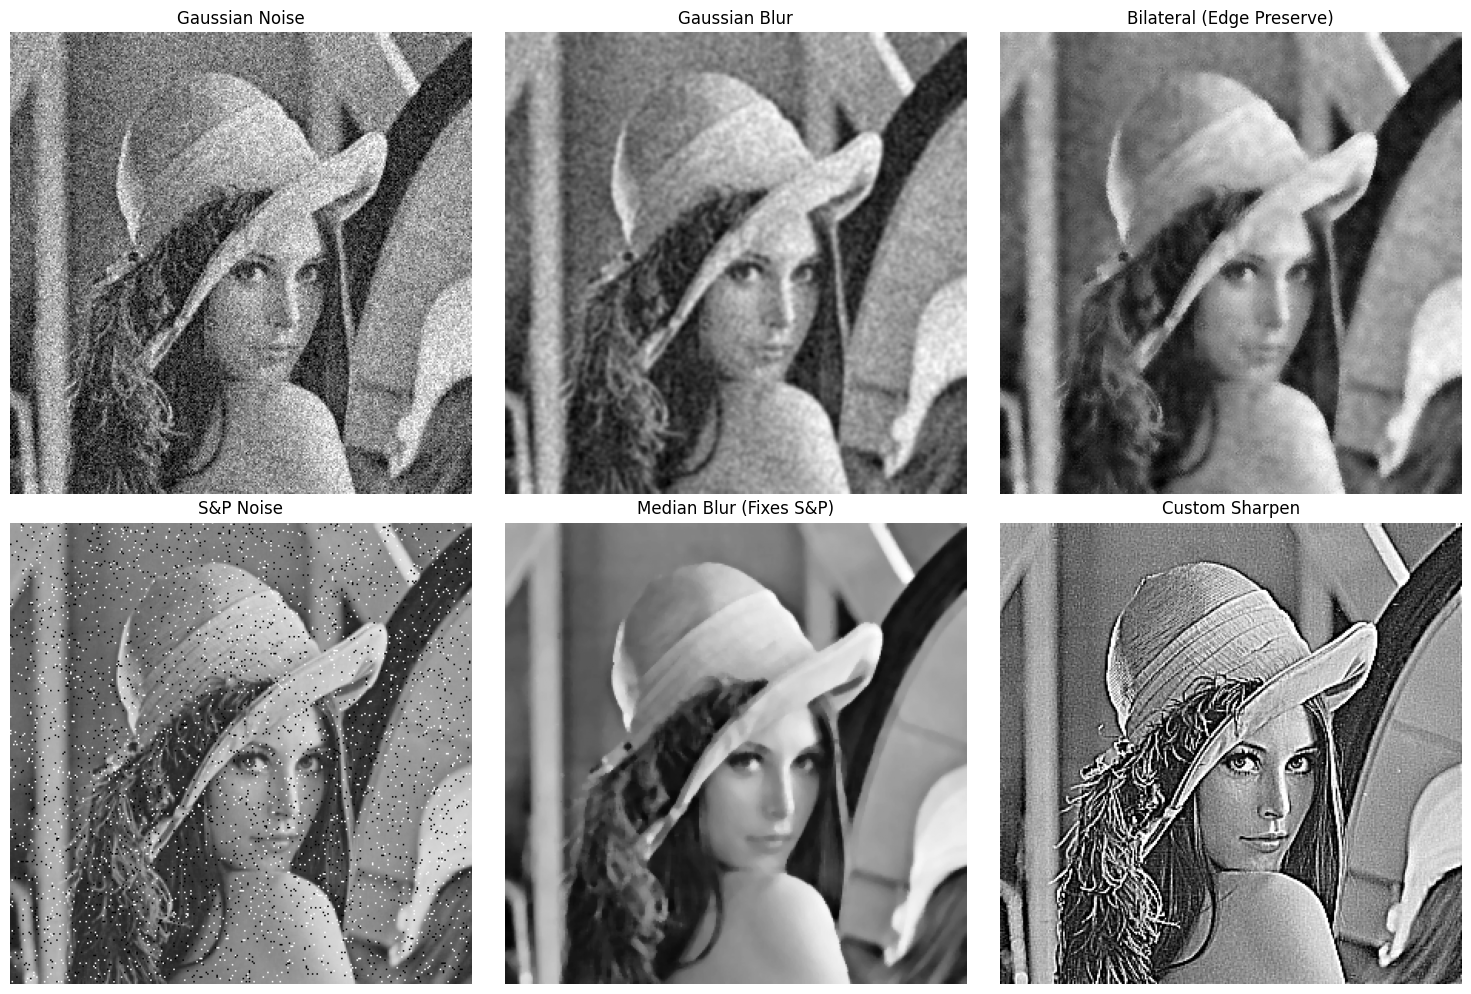

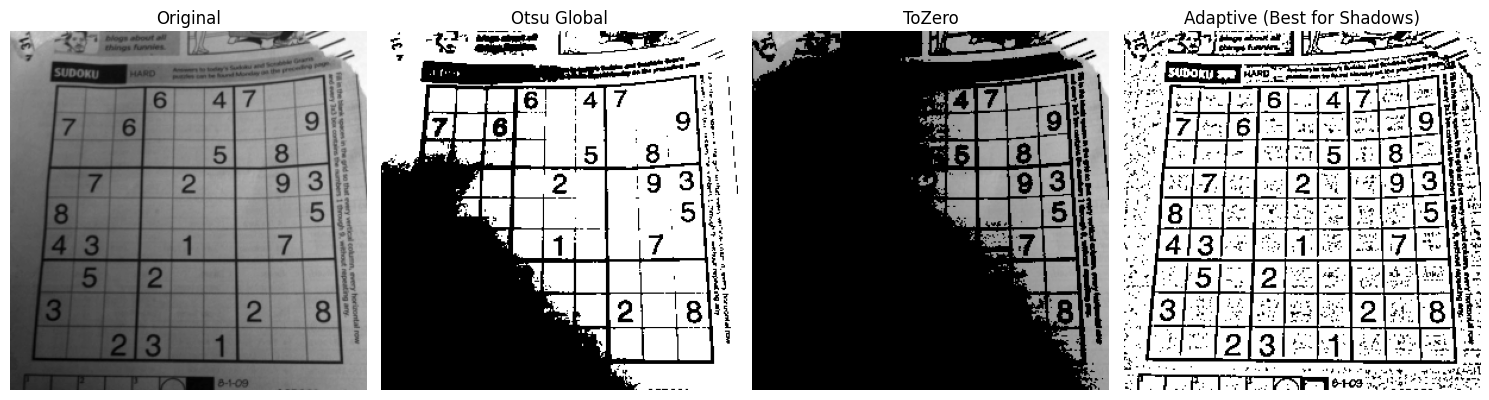

In [22]:
def add_gaussian_noise(image, mean=0, std=25):
    noise = np.random.normal(mean, std, image.shape).astype(np.float32)
    noisy = cv2.add(image.astype(np.float32), noise)
    return np.clip(noisy, 0, 255).astype(np.uint8)

def add_sp_noise(image, prob=0.05):
    noisy = np.copy(image)
    num_salt = np.ceil(prob * image.size * 0.5)
    num_pepper = np.ceil(prob * image.size * 0.5)
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape[:2]]
    noisy[tuple(coords)] = 255
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape[:2]]
    noisy[tuple(coords)] = 0
    return noisy

img_lena = cv2.cvtColor(load_image('data/images/lena.jpg'), cv2.COLOR_RGB2GRAY)
img_lena = resize_keep_ratio(img_lena, target_width=300)

# 1. Noise Generation & Standard Blurring
img_gauss_noise = add_gaussian_noise(img_lena, std=30)
img_sp_noise = add_sp_noise(img_lena, prob=0.05)

gauss_blur = cv2.GaussianBlur(img_gauss_noise, (5, 5), 0)
median_blur = cv2.medianBlur(img_sp_noise, 5)
bilateral = cv2.bilateralFilter(img_gauss_noise, 9, 75, 75)

# 2. Custom Filter (Sharpening)
kernel_sharpen = np.array([[-1,-1,-1], [-1,9,-1], [-1,-1,-1]])
sharpened = cv2.filter2D(img_lena, -1, kernel_sharpen)

show_images_grid(
    [img_gauss_noise, gauss_blur, bilateral, img_sp_noise, median_blur, sharpened], 
    ['Gaussian Noise', 'Gaussian Blur', 'Bilateral (Edge Preserve)', 'S&P Noise', 'Median Blur (Fixes S&P)', 'Custom Sharpen'], 
    2, 3, cmap='gray'
)

# 3. Thresholding
img_sudoku = cv2.cvtColor(load_image('data/images/sudoku.png'), cv2.COLOR_RGB2GRAY)
img_sudoku = resize_keep_ratio(img_sudoku, target_width=300)

_, th_otsu = cv2.threshold(img_sudoku, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, th_tozero = cv2.threshold(img_sudoku, 127, 255, cv2.THRESH_TOZERO)
th_adapt = cv2.adaptiveThreshold(img_sudoku, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)

show_images_grid([img_sudoku, th_otsu, th_tozero, th_adapt], 
                 ['Original', 'Otsu Global', 'ToZero', 'Adaptive (Best for Shadows)'], 1, 4, cmap='gray')

### 3. Image Pyramids and Fourier Transform
* **`cv2.pyrDown` and `cv2.pyrUp`**: `pyrDown` blurs the image and halves its dimensions. `pyrUp` enlarges it, but since information was lost in the previous step, the image remains blurry. Pyramids are essential for Image Blending and multi-scale feature detection.
* **Fourier Transform**: Transforms an image from the spatial domain to the frequency domain. The center of the output represents low frequencies (smooth color gradients), while the edges represent high frequencies (sharp edges and noise).
  * `cv2.dft(..., flags=cv2.DFT_COMPLEX_OUTPUT)`: Produces a complex output containing real and imaginary components.
  * `np.fft.fftshift`: Shifts the zero-frequency component to the center of the spectrum for much easier visual analysis.
  * `cv2.magnitude`: Calculates the magnitude of the spectrum using the Pythagorean theorem. A logarithmic scale `20*np.log(...)` is applied to map the massive values into a viewable image range.

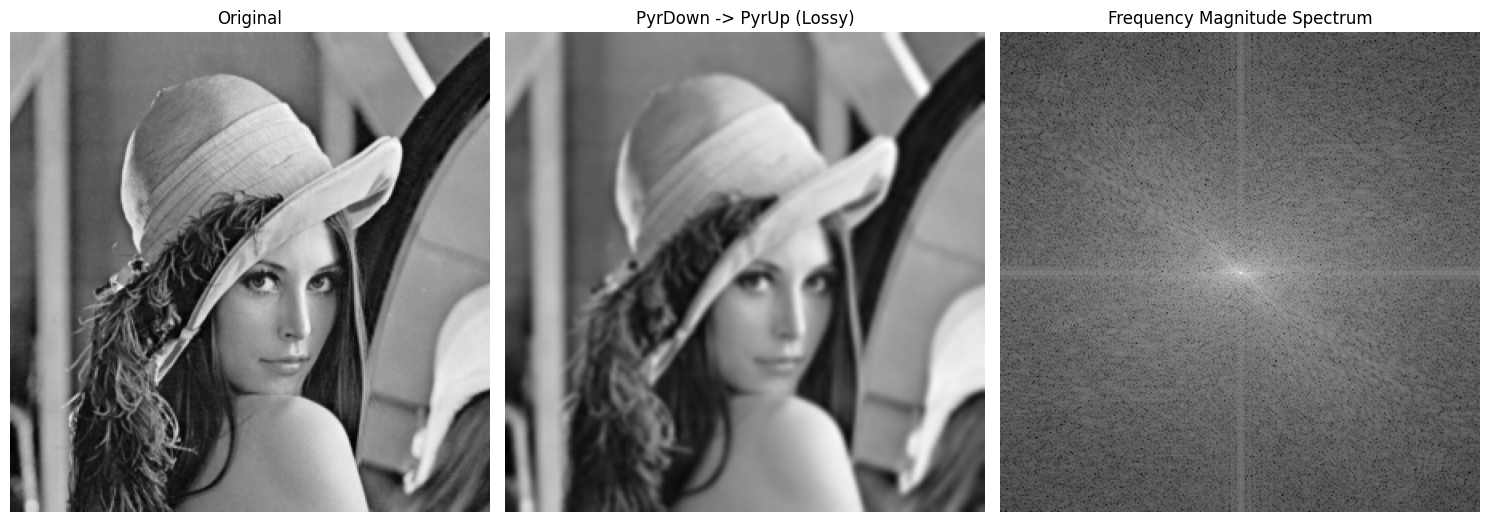

In [16]:
# Pyramids
lower_reso = cv2.pyrDown(img_lena)
higher_reso = cv2.pyrUp(lower_reso)

# Fourier Transform
dft = cv2.dft(np.float32(img_lena), flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
# Calculate magnitude and scale to logarithmic to be visible
magnitude_spectrum = 20 * np.log(cv2.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]) + 1e-5)

show_images_grid([img_lena, higher_reso, magnitude_spectrum], 
                 ['Original', 'PyrDown -> PyrUp (Lossy)', 'Frequency Magnitude Spectrum'], 1, 3, cmap='gray')

## Day 3 — Edge Detection and Gradients

### 1. Gradient Mathematics (Sobel, Laplacian) and Data Depth
When a pixel's intensity changes significantly compared to its neighbor, we detect a "slope" or derivative.
* **`cv2.Sobel(img, ddepth, dx, dy, ksize)`**: Computes the first spatial derivative. If `dx=1, dy=0`, vertical edges are highlighted.
* **Why use `cv2.CV_64F`?**: When transitioning from white (255) to black (0), the calculated derivative is negative. If we leave the output depth at `CV_8U` (unsigned 0-255), all negative slopes are truncated to zero, meaning we lose half of our edges! Thus, we compute gradients using 64-bit floats (`CV_64F`), and then take the absolute value (`np.abs` or `cv2.convertScaleAbs`) to ensure negative edges become visible.
* **`cv2.Scharr`**: A highly optimized version of Sobel, much more sensitive to subtle and fine edges.
* **`cv2.Laplacian`**: Computes the second derivative. It detects edges in all directions simultaneously but is notoriously sensitive to noise.

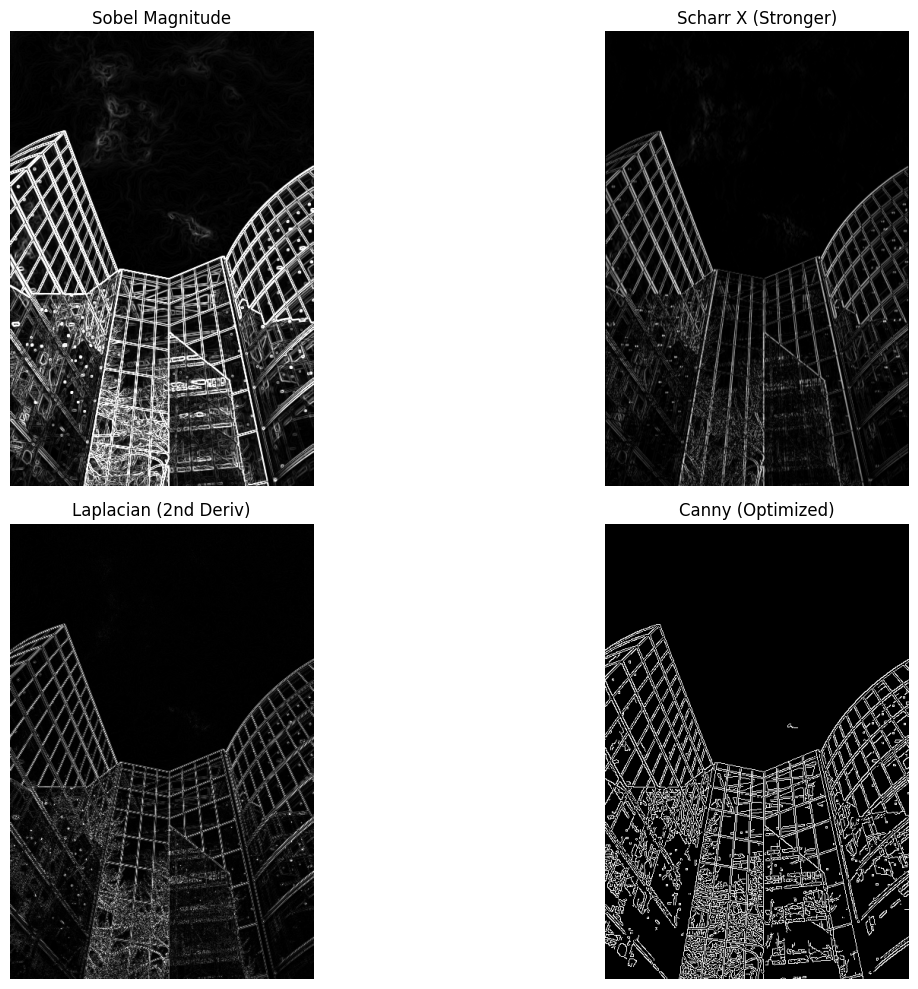

In [17]:
img_build = cv2.cvtColor(load_image('data/images/building.jpg'), cv2.COLOR_RGB2GRAY)
img_build = resize_keep_ratio(img_build, target_width=400)

# Sobel X and Y in 64-bit float to preserve negative gradients
sobel_x = cv2.Sobel(img_build, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img_build, cv2.CV_64F, 0, 1, ksize=3)
# Combine X and Y gradients using Euclidean distance
sobel_mag = np.uint8(np.clip(cv2.magnitude(sobel_x, sobel_y), 0, 255))

scharr_x = cv2.Scharr(img_build, cv2.CV_64F, 1, 0)
laplacian = cv2.convertScaleAbs(cv2.Laplacian(img_build, cv2.CV_64F))

canny_opt = cv2.Canny(img_build, 50, 150)

show_images_grid([sobel_mag, np.abs(scharr_x), laplacian, canny_opt],
                 ['Sobel Magnitude', 'Scharr X (Stronger)', 'Laplacian (2nd Deriv)', 'Canny (Optimized)'], 2, 2, cmap='gray')

## Day 4 — Morphology, Contours, and Advanced Object Geometry

### 1. Advanced Morphology (`morphologyEx`)
Modifies the binary structure of objects based on a structuring element (kernel).
* `MORPH_OPEN`: Erosion followed by Dilation (eradicates small noise).
* `MORPH_CLOSE`: Dilation followed by Erosion (fills internal holes and bridges gaps).
* `MORPH_GRADIENT`: Dilation minus Erosion. Extracts exactly the outer outline/edge of the object.
* `MORPH_TOPHAT`: Original Image minus the Opened image. Highlights bright details smaller than the kernel.
* `MORPH_BLACKHAT`: Closed image minus the Original Image. Perfect for extracting dark text on a bright background.

### 2. Comprehensive Contour Analysis
A contour is a continuous curve joining all boundary points of an object having the same color or intensity.
* **`cv2.findContours(img, mode, method)`**:
  * `mode=cv2.RETR_TREE`: Retrieves all contours and reconstructs a full hierarchy (e.g., knowing a hole is a child of the main object).
  * `method=cv2.CHAIN_APPROX_SIMPLE`: Compresses straight horizontal, vertical, and diagonal segments, keeping only their endpoints (highly memory efficient).
* **Moments `cv2.moments(cnt)`**: Calculates the physical/spatial properties of the object. The Center of Mass (Centroid) is derived via $C_x = \frac{m10}{m00}$ and $C_y = \frac{m01}{m00}$.
* **`cv2.approxPolyDP(cnt, epsilon, closed)`**: Approximates a complex contour shape with fewer vertices to reduce edge noise.
* **Bounding Geometries**: 
  * `cv2.boundingRect(cnt)`: A straight, upright rectangle `(x,y,w,h)`.
  * `cv2.minAreaRect(cnt)`: A rotated bounding box enclosing the shape with minimum area.
  * `cv2.minEnclosingCircle` and `cv2.fitEllipse`: Optimal enclosing circle and fitted ellipse.
* **`cv2.convexHull(cnt)`**: Imagine stretching a rubber band around the object; this forms the Convex Hull. `cv2.isContourConvex` checks if the shape has any indentations.
* **`cv2.findNonZero(mask)`**: Extracts the exact `(x, y)` coordinate locations of all white pixels within a provided mask.

Object Area: 5048.0 | Aspect Ratio: 1.92 | Solidity: 0.97 | Convex: False
Object Area: 4996.5 | Aspect Ratio: 0.99 | Solidity: 0.98 | Convex: False
Object Area: 5005.0 | Aspect Ratio: 0.51 | Solidity: 0.99 | Convex: False


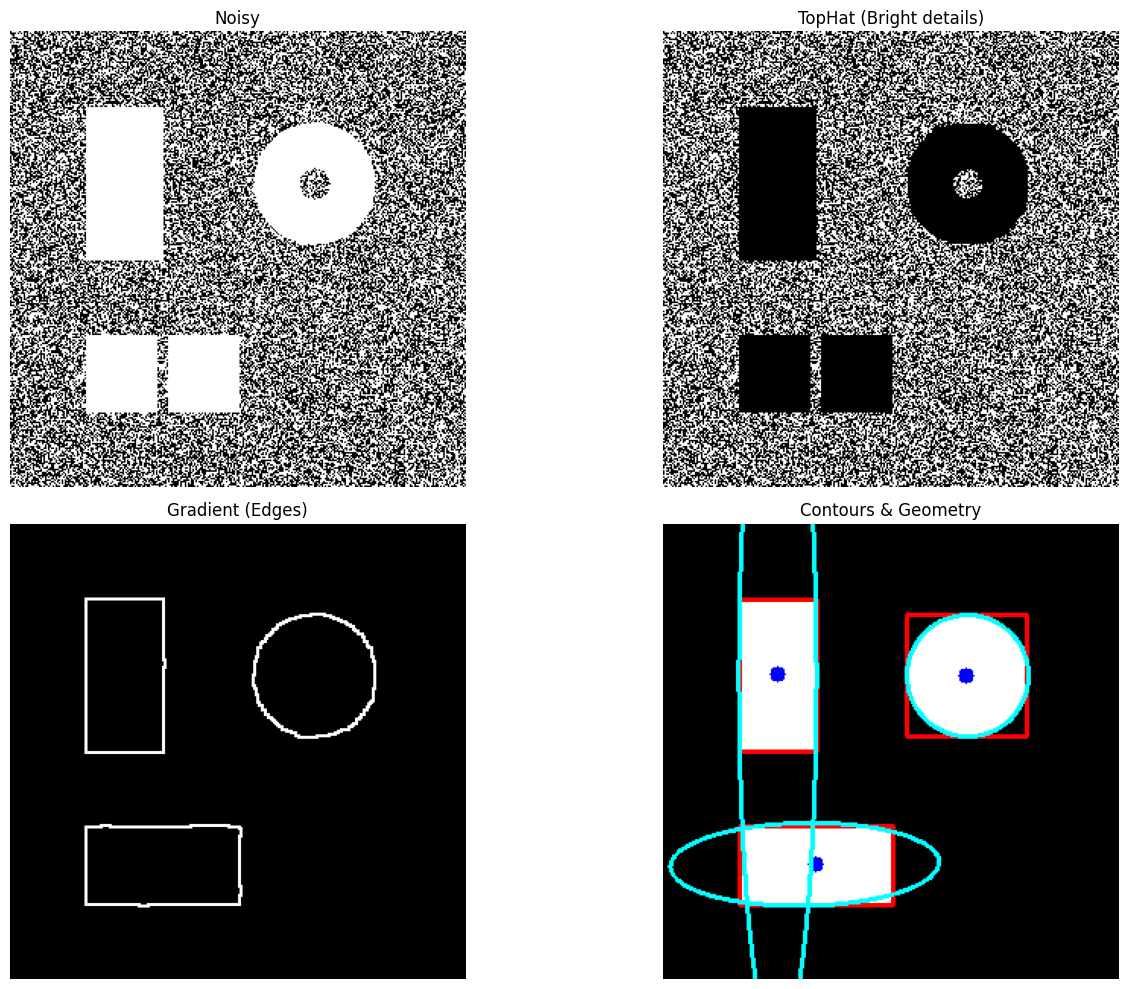

In [18]:
def generate_synthetic_binary():
    img = np.zeros((300, 300), dtype=np.uint8)
    cv2.rectangle(img, (50, 50), (100, 150), 255, -1)
    cv2.circle(img, (200, 100), 40, 255, -1)
    cv2.circle(img, (200, 100), 10, 0, -1) # Hole
    cv2.rectangle(img, (50, 200), (150, 250), 255, -1)
    cv2.line(img, (100, 190), (100, 260), 0, 5) # Break
    noise = np.random.randint(0, 2, (300, 300), dtype=np.uint8) * 255
    img[noise == 255] = 255
    return img

synth_img = generate_synthetic_binary()
kernel_small = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
kernel_large = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))

# Morphology
opened = cv2.morphologyEx(synth_img, cv2.MORPH_OPEN, kernel_small)
closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel_large)
tophat = cv2.morphologyEx(synth_img, cv2.MORPH_TOPHAT, kernel_large)
gradient = cv2.morphologyEx(closed, cv2.MORPH_GRADIENT, cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)))

# Contours
contours, hierarchy = cv2.findContours(closed, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
out_img = cv2.cvtColor(closed, cv2.COLOR_GRAY2BGR)

for cnt in contours:
    area = cv2.contourArea(cnt)
    if area < 50: continue
    
    # Moments for Centroid
    M = cv2.moments(cnt)
    if M['m00'] != 0:
        cx, cy = int(M['m10']/M['m00']), int(M['m01']/M['m00'])
        cv2.circle(out_img, (cx, cy), 5, (0, 0, 255), -1)
        
    # Rotated Bounding Box
    rect = cv2.minAreaRect(cnt)
    box = np.int32(cv2.boxPoints(rect))
    cv2.drawContours(out_img, [box], 0, (255, 0, 0), 2)
    
    # Convex Hull & Metrics
    x, y, w, h = cv2.boundingRect(cnt)
    aspect_ratio = float(w)/h
    hull = cv2.convexHull(cnt)
    solidity = float(area)/cv2.contourArea(hull) if cv2.contourArea(hull) > 0 else 0
    is_convex = cv2.isContourConvex(cnt)
    
    # Print Metrics
    print(f"Object Area: {area} | Aspect Ratio: {aspect_ratio:.2f} | Solidity: {solidity:.2f} | Convex: {is_convex}")
    
    # Ellipse
    if len(cnt) >= 5: 
        ellipse = cv2.fitEllipse(cnt)
        cv2.ellipse(out_img, ellipse, (0, 255, 255), 2)

# Find Non-Zero Pixels using Mask
mask = np.zeros_like(closed)
cv2.drawContours(mask, [contours[1]], 0, 255, -1)
pixelpoints = cv2.findNonZero(mask)

show_images_grid([synth_img, tophat, gradient, out_img],
                 ['Noisy', 'TopHat (Bright details)', 'Gradient (Edges)', 'Contours & Geometry'], 2, 2, cmap='gray')

## Day 5 — Hough Transform (Lines & Circles)

### 1. Polar Space Mathematics (Standard Hough Lines)
The `cv2.HoughLines(image, rho, theta, threshold)` function identifies infinite lines using an accumulator voting system in polar space.
* **$\rho$ and $\theta$**: Representing lines using slope and intercept ($y=mx+b$) fails for vertical lines because the slope approaches infinity. Instead, we use the perpendicular distance from the origin to the line ($\rho$) and the angle of that normal line relative to the X-axis ($\theta$).
* The function outputs $(\rho, \theta)$, not endpoints! To render the line, we multiply $\cos(\theta)$ and $\sin(\theta)$ by $\rho$ to compute a base coordinate $(x_0, y_0)$, then extend the line algorithmically by 1000 pixels in both directions.

### 2. Probabilistic Hough (`HoughLinesP`) and Hough Circles
* **`HoughLinesP`**: An optimized algorithm that directly returns finite line segments $(x_1, y_1, x_2, y_2)$. It uses `minLineLength` and `maxLineGap` to aggressively filter noise and bridge broken lines.
* **`cv2.HoughCircles`**: Detects circles using the Gradient Method.
  * `param1`: The upper threshold for the internal Canny edge detector.
  * `param2`: The accumulator threshold for circle centers (the lower the value, the more false-positive circles are detected).

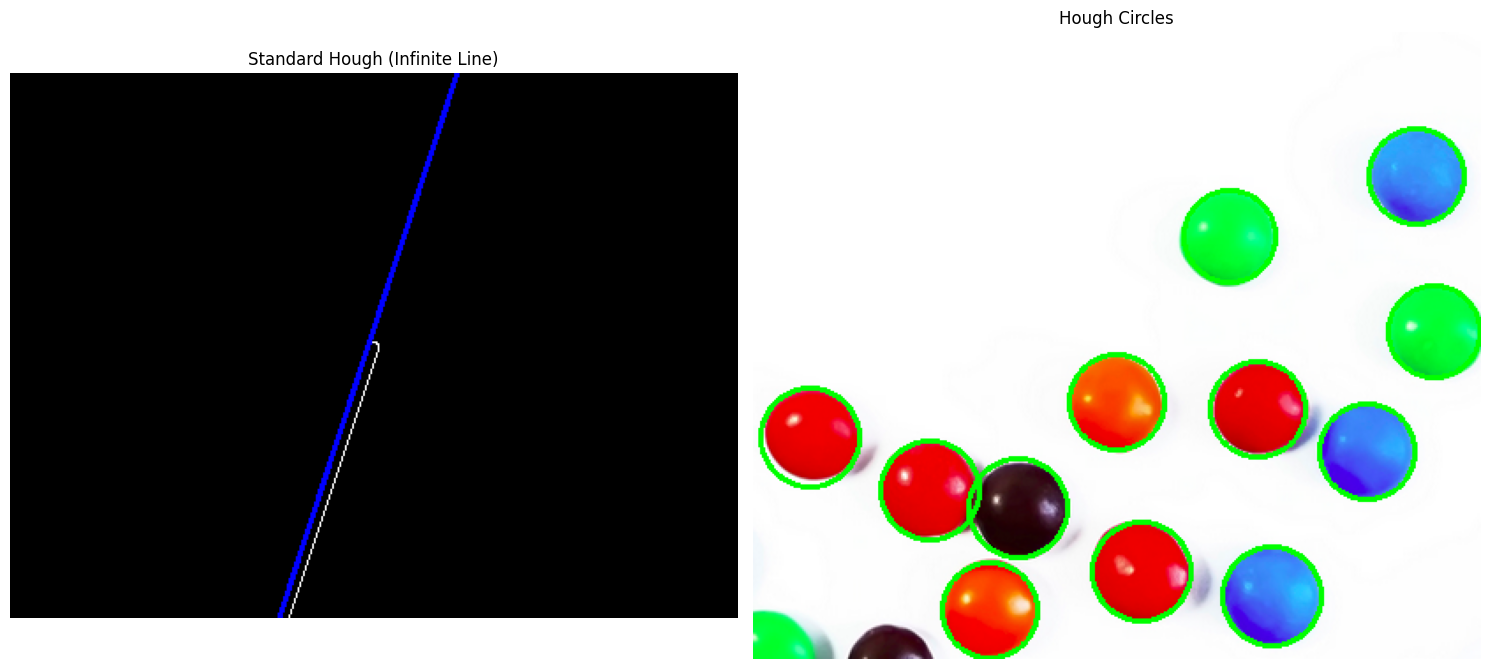

In [19]:
# Geometry Helpers
def calculate_line_angle(x1, y1, x2, y2):
    angle = math.degrees(math.atan2(y2 - y1, x2 - x1))
    if angle > 90: angle -= 180
    elif angle < -90: angle += 180
    return angle

img_lines = np.zeros((300, 400), dtype=np.uint8)
cv2.line(img_lines, (150, 300), (200, 150), 255, 3)
edges = cv2.Canny(img_lines, 50, 150)

# 1. Standard Hough Lines
lines = cv2.HoughLines(edges, 1, np.pi/180, 100)
out_std = cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)
if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a, b = math.cos(theta), math.sin(theta)
        x0, y0 = a * rho, b * rho
        # Extend the line to infinity
        cv2.line(out_std, (int(x0 + 1000*(-b)), int(y0 + 1000*(a))), (int(x0 - 1000*(-b)), int(y0 - 1000*(a))), (0, 0, 255), 2)

# 2. Hough Circles
img_smarties = load_image('data/images/smarties.png')
gray_smarties = cv2.cvtColor(img_smarties, cv2.COLOR_RGB2GRAY)
gray_smarties = cv2.medianBlur(gray_smarties, 5)

circles = cv2.HoughCircles(gray_smarties, cv2.HOUGH_GRADIENT, 1, 20, param1=50, param2=30, minRadius=15, maxRadius=40)
out_circ = img_smarties.copy()
if circles is not None:
    circles = np.uint16(np.around(circles))
    for i in circles[0, :]:
        cv2.circle(out_circ, (i[0], i[1]), i[2], (0, 255, 0), 2)

show_images_grid([out_std, out_circ], ['Standard Hough (Infinite Line)', 'Hough Circles'], 1, 2)

## Day 6 — Geometric Transforms and Template Matching

### 1. Affine vs. Perspective Transforms
* **Affine (`cv2.warpAffine`)**: A geometric transformation that keeps parallel lines parallel (e.g., rotation, translation, scaling). It requires a **2x3 matrix**. `cv2.getRotationMatrix2D` easily generates this matrix for basic rotations.
* **Perspective (`cv2.warpPerspective`)**: Simulates a 3D camera viewpoint change (Homography). Parallel lines may converge towards a vanishing point. It requires a **3x3 matrix**, which is constructed using 4 source coordinates and 4 destination coordinates via `cv2.getPerspectiveTransform`.

### 2. Template Matching (`cv2.matchTemplate`)
Slides a smaller reference image (template) over a larger source image to find the most similar region.
* **`TM_CCOEFF_NORMED`**: Computes correlation. Larger numbers signify a stronger match, so we retrieve the ideal point from the `max_loc` returned by `cv2.minMaxLoc`.
* **`TM_SQDIFF`**: Computes squared differences. A smaller number (closer to zero) indicates higher similarity, meaning we must retrieve the point from `min_loc` instead.

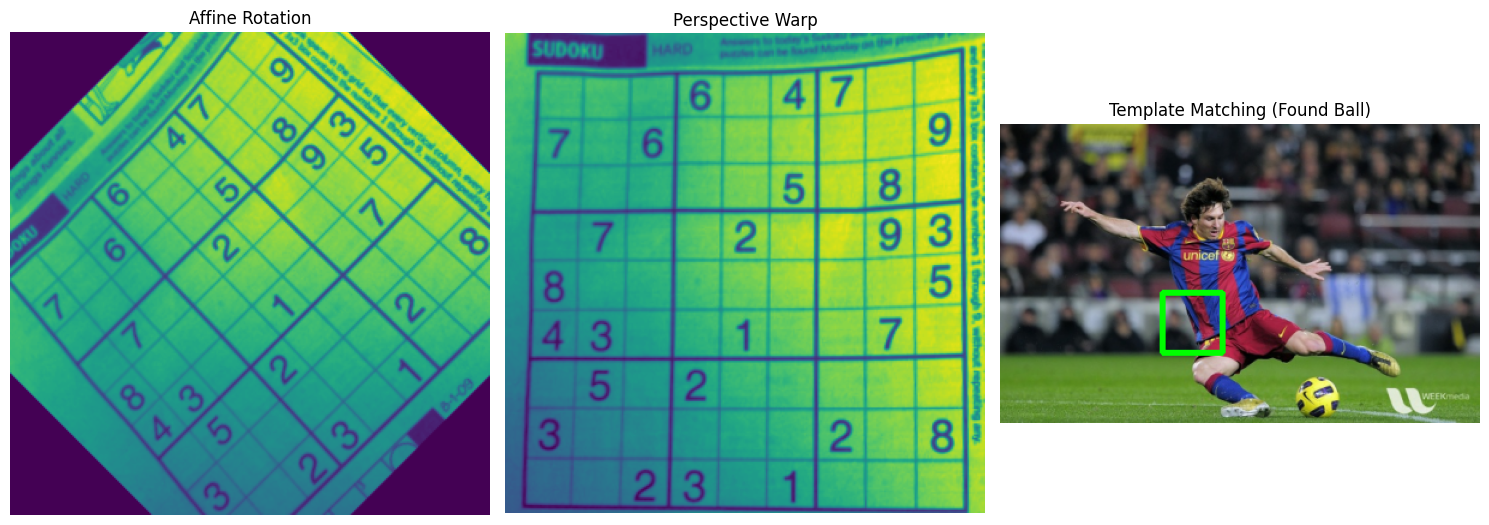

In [20]:
img_sudoku = cv2.cvtColor(load_image('data/images/sudoku.png'), cv2.COLOR_RGB2GRAY)
img_sudoku = resize_keep_ratio(img_sudoku, target_width=300)

# 1. Affine Rotation
h, w = img_sudoku.shape[:2]
M_rot = cv2.getRotationMatrix2D(((w-1)/2.0, (h-1)/2.0), 45, 1) # Rotate 45 deg
img_rotated = cv2.warpAffine(img_sudoku, M_rot, (w, h))

# 2. Perspective Transform (Bird's Eye View)
src_pts = np.float32([[23, 27], [275, 30], [8, 280], [290, 280]])
dst_pts = np.float32([[0, 0], [300, 0], [0, 300], [300, 300]])
M_persp = cv2.getPerspectiveTransform(src_pts, dst_pts)
img_warped = cv2.warpPerspective(img_sudoku, M_persp, (300, 300))

# 3. Template Matching
img_messi = load_image('data/images/messi.jpg')
img_messi = resize_keep_ratio(img_messi, target_width=400)
template = extract_roi(img_messi, 135, 140, 50, 50) # The ball
th, tw = template.shape[:2]

res = cv2.matchTemplate(img_messi, template, cv2.TM_CCOEFF_NORMED)
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)
top_left = max_loc # Because we used CCOEFF
bottom_right = (top_left[0] + tw, top_left[1] + th)
out_match = img_messi.copy()
cv2.rectangle(out_match, top_left, bottom_right, (0, 255, 0), 3)

show_images_grid([img_rotated, img_warped, out_match], 
                 ['Affine Rotation', 'Perspective Warp', 'Template Matching (Found Ball)'], 1, 3)

## Day 7 — Phase 1 Project (Expert Pipeline)

This capstone project combines all previously learned concepts into a fully autonomous, production-grade wall-line detection pipeline that is extremely robust against noise and visual distractors.
* **Synthetic Dataset Generation:** Automatically generating evaluation images injected with Gaussian noise and a hidden Ground Truth.
* **Auto-Canny:** Dynamically calculating robust Canny thresholds based on the median image intensity, eliminating the risk of hardcoded failures in varying light.
* **Heuristic Filtering:** Intelligently discarding detected Hough lines that are too vertical (e.g., cables or wall cracks) based on geometric domain knowledge.
* **Robust Line Fitting (`cv2.fitLine`)**: Leveraging the L1 norm (`cv2.DIST_L1`), this mathematical technique heavily penalizes outliers (bad data points), perfectly locking onto the true structural edge.

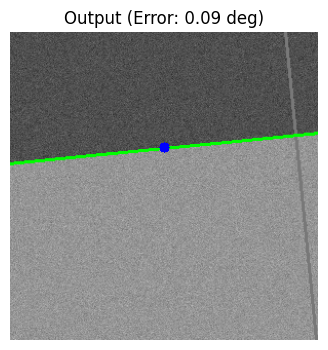

--- EVALUATION REPORT ---
Success Rate: 100.0%
Mean Angle Error: 0.10 deg


In [21]:
def generate_wall_test_set(num_samples=10):
    dataset = []
    for _ in range(num_samples):
        img = np.full((300, 300), 150, dtype=np.uint8)
        gt_angle = random.uniform(-30, 30)
        gt_y_center = random.randint(100, 200)
        rad = math.radians(gt_angle)
        dx, dy = math.cos(rad) * 400, math.sin(rad) * 400
        pt1, pt2 = (int(150 - dx), int(gt_y_center - dy)), (int(150 + dx), int(gt_y_center + dy))
        cv2.fillPoly(img, np.array([[pt1, pt2, (pt2[0], 0), (pt1[0], 0)]], dtype=np.int32), 80)
        
        # Add Noise and Distractor line
        noise = np.random.normal(0, 10, img.shape).astype(np.float32)
        img = np.clip(cv2.add(img.astype(np.float32), noise), 0, 255).astype(np.uint8)
        cv2.line(img, (random.randint(0, 300), 0), (random.randint(0, 300), 300), 120, 2)
        dataset.append({'image': img, 'gt_angle': gt_angle, 'gt_y_center': gt_y_center})
    return dataset

test_dataset = generate_wall_test_set(10)

def expert_wall_pipeline(image):
    filtered = cv2.bilateralFilter(image, 9, 75, 75)
    v = np.median(filtered)
    edges = cv2.Canny(filtered, int(max(0, (1.0 - 0.33) * v)), int(min(255, (1.0 + 0.33) * v)))
    closed_edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, np.ones((3,3), np.uint8))
    
    lines = cv2.HoughLinesP(closed_edges, 1, np.pi/180, 40, minLineLength=60, maxLineGap=20)
    if lines is None: return None
    
    valid_points = []
    for line in lines:
        x1, y1, x2, y2 = line.flatten()
        if abs(calculate_line_angle(x1, y1, x2, y2)) < 45: 
            valid_points.extend([[x1, y1], [x2, y2]])
            
    if not valid_points: return None
    valid_points = np.array(valid_points, dtype=np.int32)
    [vx, vy, x, y] = cv2.fitLine(valid_points, cv2.DIST_L1, 0, 0.01, 0.01)
    
    final_angle = math.degrees(math.atan2(vy[0], vx[0]))
    center_y = (vy[0] / vx[0]) * (150 - x[0]) + y[0]
    return final_angle, center_y, vx[0], vy[0], x[0], y[0]

success_count = 0
angle_errors = []

for i, sample in enumerate(test_dataset):
    img, gt_angle, gt_y = sample['image'], sample['gt_angle'], sample['gt_y_center']
    result = expert_wall_pipeline(img)
    if result:
        success_count += 1
        pred_angle, pred_y, vx, vy, x, y = result
        angle_errors.append(abs(pred_angle - gt_angle))
        
        if success_count == 1:
            annotated = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
            cv2.line(annotated, (int(x - vx*1000), int(y - vy*1000)), (int(x + vx*1000), int(y + vy*1000)), (0, 255, 0), 2)
            cv2.circle(annotated, (150, int(pred_y)), 5, (0,0,255), -1)
            show_image(annotated, f"Output (Error: {abs(pred_angle-gt_angle):.2f} deg)")

print(f"--- EVALUATION REPORT ---\nSuccess Rate: {success_count / len(test_dataset) * 100:.1f}%\nMean Angle Error: {np.mean(angle_errors):.2f} deg")